In [1]:
import phidl
import phidl.geometry as pg
from phidl import quickplot as qp
import numpy as np
import os
from phidl import Device, Path
import phidl.path as pp
from scipy.constants import epsilon_0, mu_0
from scipy.special import ellipk
import phidl.routing as pr

In [2]:
def make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width):
    
    pad = pg.taper(length=pad_size,width1=pad_size,width2=pad_size)
    taper = pg.taper(length=taper_len,width1=pad_size,width2=feedline_width)
    feedline = pg.taper(length=feedline_len,width1=feedline_width,width2=feedline_width)

    feedline_dev = phidl.Device("feedline")
    pad_ref1 = feedline_dev.add_ref(pad)
    taper_ref1 = feedline_dev.add_ref(taper)
    feedline_ref = feedline_dev.add_ref(feedline)
    taper_ref1.connect(1,destination=pad_ref1.ports[2])
    feedline_ref.connect(1,destination=taper_ref1.ports[2])
    taper_ref2 = feedline_dev.add_ref(taper)
    pad_ref2 = feedline_dev.add_ref(pad)
    taper_ref2.connect(2,destination=feedline_ref.ports[2])
    pad_ref2.connect(2,destination=taper_ref2.ports[1])
    feedline_dev.xmax = 0

    return feedline_dev

def make_feedline_contact(
    pad_size = 200,
    taper_len = 100,
    feedline_len = 0,
    feedline_width = 66,
    ground_gap = 2,
):
    """
    TODO: Add ports to couple resonator to!
    """
    feedline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline.x = 0

    pad_size += 100
    feedline_width += 2*ground_gap

    feedline_outline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline_outline.x = 0

    return feedline, feedline_outline

In [3]:
def make_feedline_contact(
    pad_size = 200,
    taper_len = 100,
    feedline_len = 0,
    feedline_width = 66,
    ground_gap = 2,
):
    """
    TODO: Add ports to couple resonator to!
    """
    feedline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline.x = 0

    pad_size += 100
    feedline_width += 2*ground_gap

    feedline_outline = make_feedline_sub(pad_size,taper_len,feedline_len,feedline_width)
    feedline_outline.x = 0

    return feedline, feedline_outline

In [4]:
def make_coupling_elbow(
        coupling_length,
        turn_radius = 25,
        space = 100
    ):

    P = Path()
    P.append(pp.straight(coupling_length))
    direction = 1
    P.append(pp.euler(radius=turn_radius, angle=90*direction))
    P.append(pp.straight(space))

    return P

def make_coupling_hammerhead(
        coupling_length,
        coupling_width=5
    ):
    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    return hammerhead

total length 350.0


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


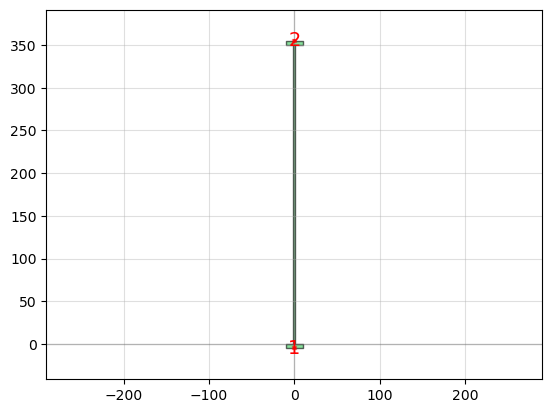

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


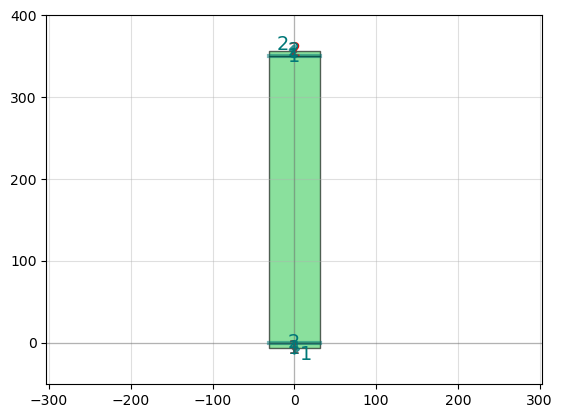

In [5]:
def make_lamda2_res_straight(
    radius=50,
    width=2,
    center_pin_length=3500,
    center_pin_gap = 60,
    coupling_length = 100,
    coupling_width=5,
    hammerhead_gap=2
):

    P = Path()
    P.append(pp.straight(center_pin_length))

    print('total length',P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

coupled_resonator, coupled_resonator_outline = make_lamda2_res_straight(center_pin_length=350,center_pin_gap=30,coupling_length=20,coupling_width=5)
qp(coupled_resonator)
qp(coupled_resonator_outline)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


total length 350.0


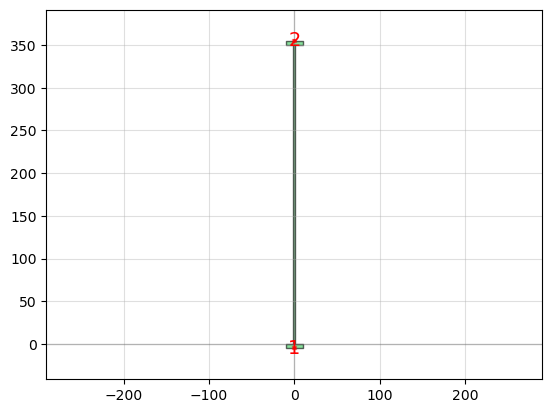

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


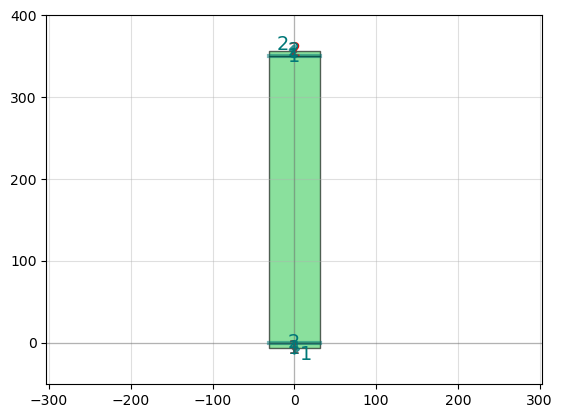

In [6]:
coupled_resonator, coupled_resonator_outline = make_lamda2_res_straight(center_pin_length=350,center_pin_gap=30,coupling_length=20,coupling_width=5)
qp(coupled_resonator)
qp(coupled_resonator_outline)

In [7]:
def calculate_segment_length(
    L_len=400,
    radius=200
):
    P = Path()
    direction = -1
    P.append(pp.straight(2*radius))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180*direction))
    P.append(pp.straight(L_len))
    direction *= -1
    P.append(pp.arc(radius=radius, angle=-90*direction))
    return P.length()

In [8]:
#TODO: Define a sub!

In [9]:
def make_lamda2_res_meander(
    L_len=300,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
    coupling_length = 20,
    coupling_width=5,
    space=100,
    hammerhead_gap=2
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    if coupling_length < width:
            coupling_length = width

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [10]:
def smooth_device(r,smoothing_radius=2):
    r_round = phidl.Device("round_r")
    for port in r.ports.values():
        r_round.add_port(port)
    dev = pg.union(r, precision=1e-6, layer=0)   # instead of boolean with B=None
    dev.flatten()
    for ps in dev.polygons:
        ps.fillet(radius=smoothing_radius)
        for pts in ps.polygons:          # a PolygonSet can hold several polygons
            r_round.add_polygon(pts, layer=0)
    return r_round

### Define resonators!

In [ ]:
# resonator_params = [(175,128,16,4500,50),(150,120,14,5000,50),(120,112,12,6000,50),(100,104,10,7000,50),(85,96,8,8000,50),(55,88,6,9000,50)]

# (coupling_length,center_pin_width,ground_plane_gap,total_length,coupling_width)

resonator_params = [(60,50,100,8000,50),(60,45,85,8250,50),(60,40,70,8500,50),(60,35,55,8750,50),(60,30,40,9000,50)]

hammerhead_gaps = [175,150,120,100,85,55]

common_params = dict(
    L_len=350,
    radius=200,
    coupling_width=20
)

resonators = []
outlines = []
for (hammerhead_gap,width,center_pin_gap,center_pin_length,coupling_length) in resonator_params:
    res, outline = make_lamda2_res_meander(hammerhead_gap=hammerhead_gap,width=width, center_pin_gap=center_pin_gap, center_pin_length=center_pin_length, coupling_length = coupling_length,**common_params)
    resonators.append(res)
    outlines.append(outline)

pad_size = 250
taper_len = 100
feedline_len = 7000
feedline_width = 80
ground_gap = 4

feedline, feedline_outline = make_feedline_contact(    
    pad_size = pad_size,
    taper_len = taper_len,
    feedline_len = feedline_len,
    feedline_width = feedline_width,
    ground_gap = ground_gap
    )

feedline.add_port(0,midpoint=(-feedline_len/3,feedline_width/2),orientation=90)
feedline.add_port(1,midpoint=(0,feedline_width/2),orientation=90)
feedline.add_port(2,midpoint=(feedline_len/3,feedline_width/2),orientation=90)
feedline.add_port(3,midpoint=(-feedline_len/3,-feedline_width/2),orientation=-90)
feedline.add_port(4,midpoint=(0,-feedline_width/2),orientation=-90)
feedline.add_port(5,midpoint=(feedline_len/3,-feedline_width/2),orientation=-90)

8000.0
8250.0
8500.0
8750.0
9000.0


Port (name 5, midpoint [2333.33333333  -40.        ], width 1, orientation 270)

In [12]:
# Define vortex pinning lattice.
sq = pg.rectangle(size = (5,5))
device_list = []
i = int(10e3//100)
j = int(10e3//100)

for obj in range(i*j):
    device_list.append(sq)

# lattice_device = phidl.geometry.grid(
#     device_list=[device_list],
#     spacing=(100, 100),     # X and Y distance between elements
#     separation=True,    # True = fixed gap size; False = even center-to-center spacing
#     shape=(i,j)        # Dimensions of the grid grid (columns, rows)
# )

groundplane = pg.rectangle(size=(10000,10000))
# groundplane = pg.boolean(groundplane,lattice_device,operation='A-B')
# groundplane.write_gds("groundplane.gds")

In [13]:
current, current_outline = make_feedline_contact(    
    pad_size = 250,
    taper_len = 50,
    feedline_len = 800,
    feedline_width = 100,
    ground_gap = 25
    )

voltage, voltage_outline = make_feedline_contact(    
    pad_size = 250,
    taper_len = 50,
    feedline_len = 400,
    feedline_width = 10,
    ground_gap = 25
    )

def make_hallbar(current,voltage1):

    hallbar = phidl.Device('hallbar')
    current_ref = hallbar.add_ref(current)
    current_ref.x=0

    voltage_ref1 = hallbar.add_ref(voltage1)
    voltage_ref1.rotate(90)
    voltage_ref1.y = 0
    voltage_ref1.x = -750/3

    voltage_ref2 = hallbar.add_ref(voltage1)
    voltage_ref2.rotate(90)
    voltage_ref2.y = 0
    voltage_ref2.x = 750/3

    return hallbar

In [14]:
marker = pg.rectangle(size = (20,20))
marker.x=0
marker.y=0

center_marker = pg.rectangle(size = (5,5))
marker.x=0
marker.y=0

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


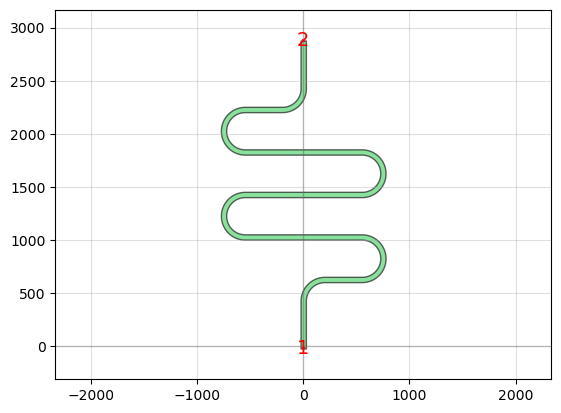

In [15]:
qp(resonators[0])

In [16]:
def make_nanowire(
    L_len=300,
    radius=150,
    width=2,
    center_pin_length=7000,
    center_pin_gap = 60,
):

    P = Path()
    direction = -1
    P.append(pp.arc(radius=radius, angle=90 * direction))
    P.append(pp.straight(L_len))
    P.append(pp.arc(radius=radius, angle=-180 * direction))
    P.append(pp.straight(L_len))
    add_length = calculate_segment_length(L_len=L_len,radius=radius)
    total_length = P.length()
    while total_length < (center_pin_length-add_length):

        P.append(pp.straight(2*radius))
        P.append(pp.straight(L_len))
        P.append(pp.arc(radius=radius, angle=180 * direction))
        P.append(pp.straight(L_len))
        direction *= -1
        total_length = P.length()

    P.append(pp.arc(radius=radius, angle=90 * direction))
    total_length = P.length()

    remaining_len = center_pin_length - P.length()
    if remaining_len < 0:
        print("ERROR! NEGATIVE LENGTH!")

    P = pp.straight(remaining_len/2).append(P)
    P = P.append(pp.straight(remaining_len/2))

    print(P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupled_nanowire = D

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupled_nanowire_outline = D

    return coupled_nanowire, coupled_nanowire_outline

In [17]:
smooth = True

chip_layout = phidl.Device('chip_layout')
groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

if smooth:
    feedline = smooth_device(feedline)
    feedline_outline = smooth_device(feedline_outline)
    resonators = [smooth_device(res) for res in resonators]
    outlines = [smooth_device(outline) for outline in outlines]

# Subtract the ground plane gaps.
feedline_ref = chip_layout.add_ref(feedline)
feedline_outline_ref = chip_layout.add_ref(feedline_outline)

feedline_ref.y = 1000
feedline_outline_ref.y = 1000

# Add feedline.
chip_layout = pg.boolean(chip_layout,feedline_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,feedline_ref,operation='A+B')

for i in [0,1,2]:
    res = resonators[i]
    res_outline = outlines[i]
    hammerhead_gap = hammerhead_gaps[i]
    res_ref = chip_layout.add_ref(res)
    res_outline_ref = chip_layout.add_ref(res_outline)
    port = feedline_ref.ports[i]

    res_outline_ref.x = port.midpoint[0]
    res_outline_ref.ymin = port.midpoint[1] 

    res_ref.x = port.midpoint[0]
    res_ref.ymin = port.midpoint[1] + hammerhead_gap

    chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

for i in [3,4,5]:
    res = resonators[i]
    res_outline = outlines[i]
    hammerhead_gap = hammerhead_gaps[i]
    res_ref = chip_layout.add_ref(res)
    res_outline_ref = chip_layout.add_ref(res_outline)
    port = feedline_ref.ports[i]

    res_outline_ref.x = port.midpoint[0]
    res_outline_ref.ymax = port.midpoint[1] 

    res_ref.x = port.midpoint[0]
    res_ref.ymax = port.midpoint[1] - hammerhead_gap

    chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

for (x,y) in [(3000,-3500),(-3000,-3500)]:

    hallbar = make_hallbar(current,voltage)
    hallbar_outline = make_hallbar(current_outline,voltage_outline)

    hallbar_ref = chip_layout.add_ref(hallbar)
    hallbar_outline_ref = chip_layout.add_ref(hallbar_outline)

    hallbar_ref.x = x
    hallbar_ref.y = y
    hallbar_outline_ref.x = x
    hallbar_outline_ref.y = y

    chip_layout = pg.boolean(chip_layout,hallbar_outline_ref,operation='A-B')
    chip_layout = pg.boolean(chip_layout,hallbar_ref,operation='A+B')

marker_locs = [(1200,1200)]
for marker_loc in marker_locs:
    for xmag in [-1,1]:
        for ymag in [0,-1,1,-2,2,-3,3]:
            xloc = xmag*marker_loc[0]
            yloc = ymag*marker_loc[1]
            marker_ref = chip_layout.add_ref(marker)
            center_marker_ref = chip_layout.add_ref(center_marker)
            marker_ref.x = xloc
            marker_ref.y = yloc
            center_marker_ref.x = xloc
            center_marker_ref.y = yloc
            chip_layout = pg.boolean(chip_layout,marker_ref,operation='A-B')
            chip_layout = pg.boolean(chip_layout,center_marker_ref,operation='A+B')

qp(chip_layout)
# chip_layout.write_gds('102526_nbn_res_chip.gds')

IndexError: list index out of range

In [ ]:
nanowire, nanowire_outline = make_nanowire(
    L_len=100,
    radius=25,
    width=1,
    center_pin_length=900,
    center_pin_gap = 100
)

nanowire.x = 0
nanowire.y = -3500
nanowire_outline.x = 0
nanowire_outline.y = -3500

diff = pg.boolean(nanowire_outline,nanowire,operation='A-B')

diff.remap_layers({0:2})

900.0


Device (name "boolean" (uid 353), ports [], aliases [], 2 polygons, 0 references)

In [ ]:
negative_mask = pg.invert(chip_layout,border=0,layer=1)
ground_plane_ref = negative_mask.add_ref(groundplane)
ground_plane_ref.x=0
ground_plane_ref.y=0

negative_mask.add_ref(diff)

# negative_mask.write_gds('102526_neg_nbn_res_chip.gds')

'102526_neg_nbn_res_chip.gds'

In [ ]:
hallbar = make_hallbar(current,voltage)
hallbar_outline = make_hallbar(current_outline,voltage_outline,voltage_outline)

sub = pg.boolean(hallbar_outline,hallbar,operation='A-B')
qp(sub)

TypeError: make_hallbar() takes 2 positional arguments but 3 were given

In [ ]:
def make_lamda2_res_straight(
    radius=50,
    width=2,
    center_pin_length=3500,
    center_pin_gap = 60,
    coupling_length = 100,
    coupling_width=5,
    hammerhead_gap=2
):

    P = Path()
    P.append(pp.straight(center_pin_length))

    print('total length',P.length())

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width, ports = (1,2))

    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    coupling_length = width

    hammerhead = pg.rectangle(size=(coupling_length,coupling_width))
    hammerhead.add_port(1,midpoint=(coupling_length/2,coupling_width),orientation=90)
    hammerhead.add_port(2,midpoint=(coupling_length/2,0),orientation=-90)

    coupled_resonator = phidl.Device('coupled_resonator')
    resonator_ref = coupled_resonator.add_ref(D)
    hh_ref1 = coupled_resonator.add_ref(hammerhead)
    hh_ref1.connect(2,resonator_ref.ports[1])
    hh_ref2 = coupled_resonator.add_ref(hammerhead)
    hh_ref2.connect(1,resonator_ref.ports[2])
    coupled_resonator = pg.union(coupled_resonator, by_layer=False, precision=1e-6, join_first=True, max_points=0, layer=0)

    coupled_resonator.add_port(hh_ref1.ports[1])
    coupled_resonator.add_port(hh_ref2.ports[2])

    D = Device('meander')
    X = phidl.CrossSection()
    X.add(width = width+2*center_pin_gap, ports = (1,2))
    D << P.extrude(X)
    D.add_port(D.references[0].ports[1])
    D.add_port(D.references[0].ports[2])

    hammerhead = pg.rectangle(size=(2*center_pin_gap+width,coupling_width+hammerhead_gap))
    hammerhead.add_port(1,midpoint=((2*center_pin_gap+width)/2,coupling_width+hammerhead_gap),orientation=90)
    hammerhead.add_port(2,midpoint=((2*center_pin_gap+width)/2,0),orientation=-90)
    
    coupled_resonator_outline = phidl.Device('outline_coupled_resonator')
    ref_D_outline = coupled_resonator_outline.add_ref(D)
    hh_ref1 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref1.connect(2,ref_D_outline.ports[1])
    hh_ref2 = coupled_resonator_outline.add_ref(hammerhead)
    hh_ref2.connect(1,ref_D_outline.ports[2])

    coupled_resonator_outline.add_port(hh_ref1.ports[1])
    coupled_resonator_outline.add_port(hh_ref2.ports[2])
    
    coupled_resonator.rotate(90)
    coupled_resonator_outline.rotate(90)

    return coupled_resonator, coupled_resonator_outline

In [ ]:
# Groundplane with vortex traps.
groundplane = pg.rectangle(size=(10e3,10e3))

# Define vortex pinning lattice.
sq = pg.rectangle(size = (5,5))
device_list = []
i = int(10e3//100)
j = int(10e3//100)

for obj in range(i*j):
    device_list.append(sq)

lattice_device = phidl.geometry.grid(
    device_list=[device_list],
    spacing=(100, 100),     # X and Y distance between elements
    separation=True,    # True = fixed gap size; False = even center-to-center spacing
    shape=(i,j)        # Dimensions of the grid grid (columns, rows)
)

groundplane = pg.boolean(groundplane,lattice_device,operation='A-B')
groundplane.write_gds("groundplane.gds")

groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

In [21]:
# groundplane = pg.boolean(groundplane,lattice_device,operation='A-B')
# groundplane.write_gds("groundplane.gds")

groundplane = pg.rectangle(size=(25e3,25e3))

groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


total length 8000.000000000001


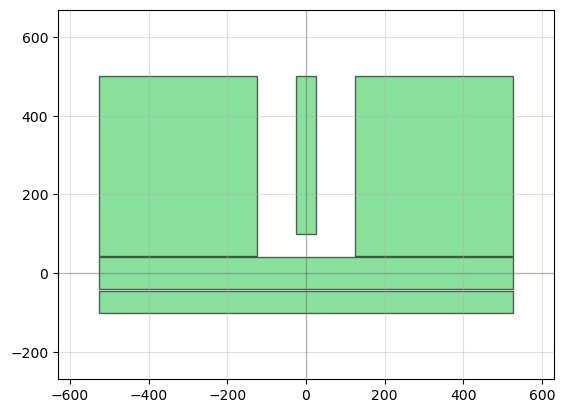

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


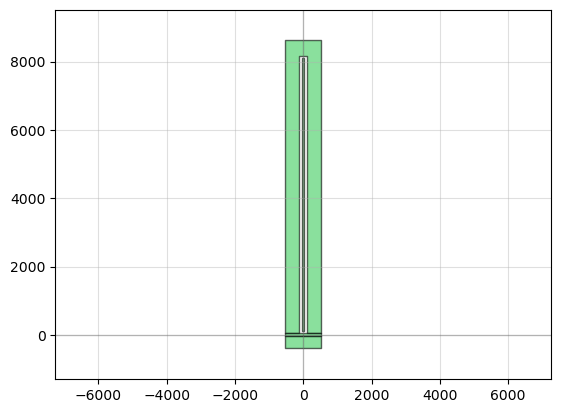

'11_01_26_lambda2_res_50um_100um_60um.gds'

In [23]:
# resonator_params = [(128,16,4500),(120,14,5000),(112,12,6000),(104,10,7000),(96,8,8000),(88,6,9000)]

resonator_params = [(60,50,100,8000,50),(60,45,85,8250,50),(60,40,70,8500,50),(60,35,55,8750,50),(60,30,40,9000,50)]

idx = 0
hammerhead_gap,center_pin_width,ground_plane_gap,center_pin_length,coupling_length = resonator_params[idx]

res, res_outline = make_lamda2_res_straight(center_pin_length=center_pin_length,width=center_pin_width,center_pin_gap=ground_plane_gap,coupling_length=coupling_length,coupling_width = 10,hammerhead_gap=hammerhead_gap)

chip_layout = phidl.Device('chip_layout')

groundplane_ref = chip_layout.add_ref(groundplane)
groundplane_ref.x=0
groundplane_ref.y=0

# Subtract the ground plane gaps.
feedline_ref = chip_layout.add_ref(feedline)
feedline_outline_ref = chip_layout.add_ref(feedline_outline)
chip_layout = pg.boolean(chip_layout,feedline_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,feedline_ref,operation='A+B')

res_ref = chip_layout.add_ref(res)
res_outline_ref = chip_layout.add_ref(res_outline)
port = feedline.ports[1]

res_outline_ref.x = port.midpoint[0]
res_outline_ref.ymin = port.midpoint[1] 

res_ref.x = port.midpoint[0]
res_ref.ymin = port.midpoint[1] + hammerhead_gap

chip_layout = pg.boolean(chip_layout,res_outline_ref,operation='A-B')
chip_layout = pg.boolean(chip_layout,res_ref,operation='A+B')

b = res_ref.bbox
padding = 500
bbox = [
    [b[0][0] - padding, -100],  # xmin - pad, ymin - pad
    [b[1][0] + padding, 500]   # xmax + pad, ymax + pad
]
bbox = pg.bbox(bbox)
cutout = pg.boolean(bbox,chip_layout,operation='and')
qp(cutout)
cutout.write_gds(f'11_01_26_lambda2_coupling_{center_pin_width}um_{ground_plane_gap}um_{hammerhead_gap}um.gds')

bbox = [
    [b[0][0] - padding, b[0][1] - padding],  # xmin - pad, ymin - pad
    [b[1][0] + padding, b[1][1] + padding]   # xmax + pad, ymax + pad
]
bbox = pg.bbox(bbox)
cutout = pg.boolean(bbox,chip_layout,operation='and')
qp(cutout)
cutout.write_gds(f'11_01_26_lambda2_res_{center_pin_width}um_{ground_plane_gap}um_{hammerhead_gap}um.gds')